4.0. Student Name: Quang Trung Nguyen

In [1]:
#install lib
!pip install seaborn
!pip install scipy

In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (8, 5)
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 30)
pd.set_option('display.precision', 3)

#read files
df = pd.read_csv('student_performance_dataset.csv')  

#Descriptive statistics
numeric_variables = [
    'study_time_hours',
    'attendance_percent',
    'sleep_hours',
]
categorical_variables = [
    'internet_access',
    'extracurricular_activities',
    'part_time_job'
]
target_variable = ['final_exam_score']

analysis_variables = numeric_variables + categorical_variables + target_variable

df=df[analysis_variables]


4.2.1. Dataset description

In [3]:
print("Shape:", df.shape) 
print("\nColumn names:", df.columns.tolist())
print("\nData types:\n", df.dtypes)
df.head(10)  

Shape: (1000, 7)

Column names: ['study_time_hours', 'attendance_percent', 'sleep_hours', 'internet_access', 'extracurricular_activities', 'part_time_job', 'final_exam_score']

Data types:
 study_time_hours              float64
attendance_percent            float64
sleep_hours                   float64
internet_access                object
extracurricular_activities     object
part_time_job                  object
final_exam_score              float64
dtype: object


,study_time_hours,attendance_percent,sleep_hours,internet_access,extracurricular_activities,part_time_job,final_exam_score
0,4.0,98.0,6.5,Yes,Yes,No,100.0
1,6.3,100.0,5.7,Yes,Yes,Yes,100.0
2,4.9,85.3,7.9,Yes,No,Yes,97.3
3,2.6,77.5,8.0,Yes,Yes,No,83.8
4,2.2,89.6,4.6,Yes,No,Yes,68.3
5,4.2,78.2,5.7,Yes,No,No,81.6
6,1.5,100.0,5.0,Yes,Yes,Yes,69.6
7,6.2,86.4,6.0,Yes,Yes,No,88.0
8,5.3,81.3,6.7,Yes,No,No,84.4
9,2.8,86.8,5.1,Yes,Yes,No,74.3


Data Preparation

In [4]:
print("-------MISSING VALUE---------")
missing = df.isnull().sum()
print(missing)
print("Total missing values:", df.isnull().sum().sum())
print("-----------------------------")


print("\n-------DUPLICATE---------")
print("Duplicate rows:", df.duplicated().sum())
print("-----------------------------")


print("\n-------CHECK INVALID VALUES---------")
for col in numeric_variables + target_variable:
    print(col, ":", df[col].min(), "-", df[col].max())
for col in categorical_variables:
    print(col, ":",df[col].unique())

print("-----------------------------")


-------MISSING VALUE---------
study_time_hours              0
attendance_percent            0
sleep_hours                   0
internet_access               0
extracurricular_activities    0
part_time_job                 0
final_exam_score              0
dtype: int64
Total missing values: 0
-----------------------------

-------DUPLICATE---------
Duplicate rows: 0
-----------------------------

-------CHECK INVALID VALUES---------
study_time_hours : 0.5 - 8.1
attendance_percent : 54.8 - 100.0
sleep_hours : 3.2 - 10.0
final_exam_score : 46.8 - 100.0
internet_access : ['Yes' 'No']
extracurricular_activities : ['Yes' 'No']
part_time_job : ['No' 'Yes']
-----------------------------


4.2.4. EDA: Numeric Variables - study_time_hours, attendance_percent, sleep_hours

In [5]:
from scipy.stats import linregress

summary = df[numeric_variables + target_variable].agg([
    'mean',
    'median',
    'std',
    'min',
    'max'
])
summary




,study_time_hours,attendance_percent,sleep_hours,final_exam_score
mean,3.571,85.092,6.800,83.543
median,3.600,85.200,6.800,83.800
std,1.479,9.271,1.204,10.341
min,0.500,54.800,3.200,46.800
max,8.100,100.000,10.000,100.000


Correlation Heatmap


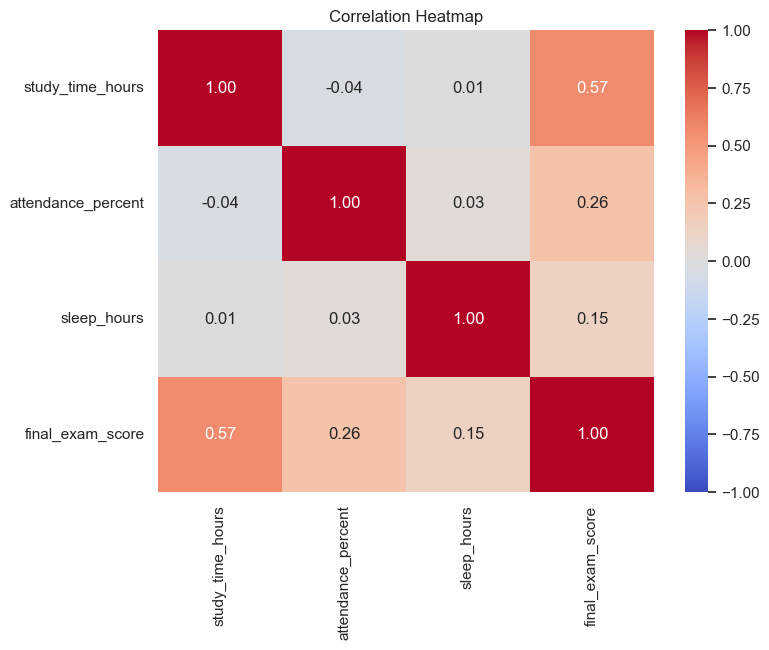

In [6]:
corr = df[numeric_variables + target_variable].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    corr,
    annot = True,
    cmap = 'coolwarm',
    fmt = '.2f',
    vmin = -1,
    vmax = 1
)

print('Correlation Heatmap')
plt.title('Correlation Heatmap')
plt.show()

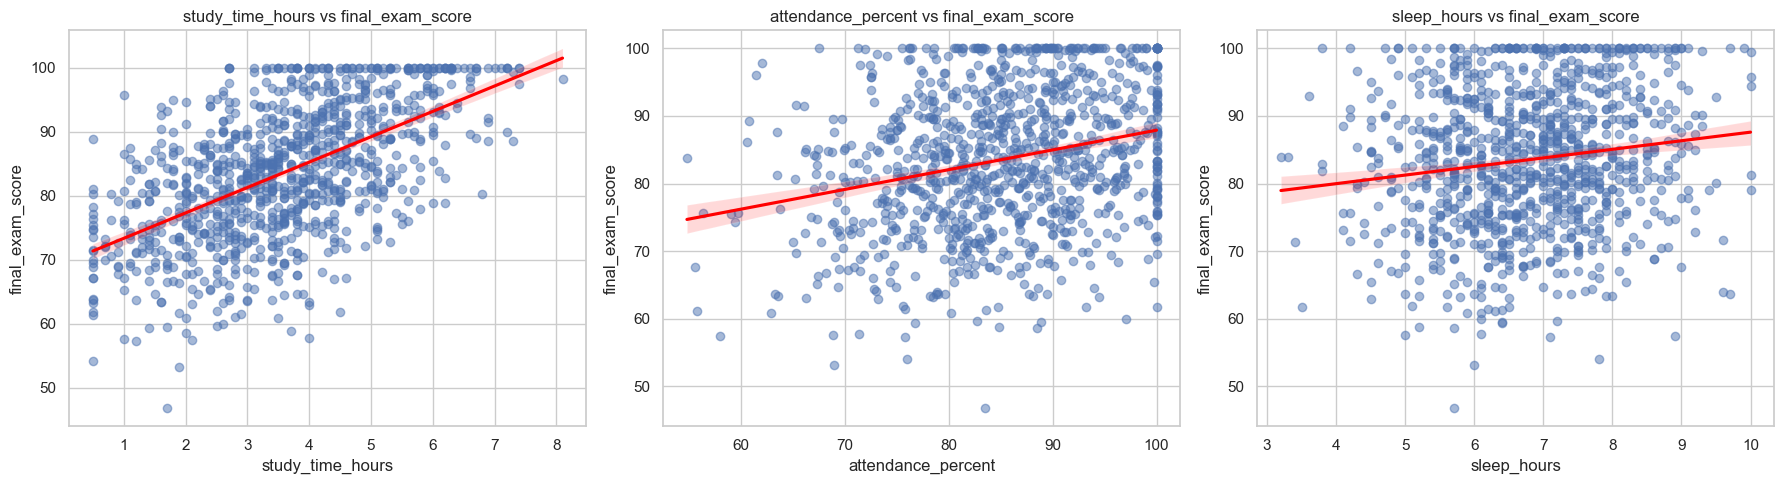

In [7]:

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, var in zip(axes, numeric_variables):
    sns.regplot(
        data=df,
        x=var,
        y='final_exam_score',
        scatter_kws={'alpha': 0.5},
        line_kws={'color': 'red'},
        ax=ax
    )

    ax.set_title(f'{var} vs final_exam_score')
    ax.set_xlabel(var)
    ax.set_ylabel('final_exam_score')

plt.tight_layout()
plt.show()



In [8]:


results = []

for var in numeric_variables:
    result = linregress(
        df[var],
        df[target_variable[0]]
    )

    results.append({
        'Variable': var,
        'Slope': result.slope,
        'R-squared': result.rvalue ** 2,
        'p-value': result.pvalue
    })

results_df = pd.DataFrame(results)

results_df.round(4)

,Variable,Slope,R-squared,p-value
0,study_time_hours,3.969,0.322,0.0
1,attendance_percent,0.292,0.069,0.0
2,sleep_hours,1.270,0.022,0.0


4.2.4. EDA: Categorical Variables - internet_access, extracurricular_activities, part_time_job

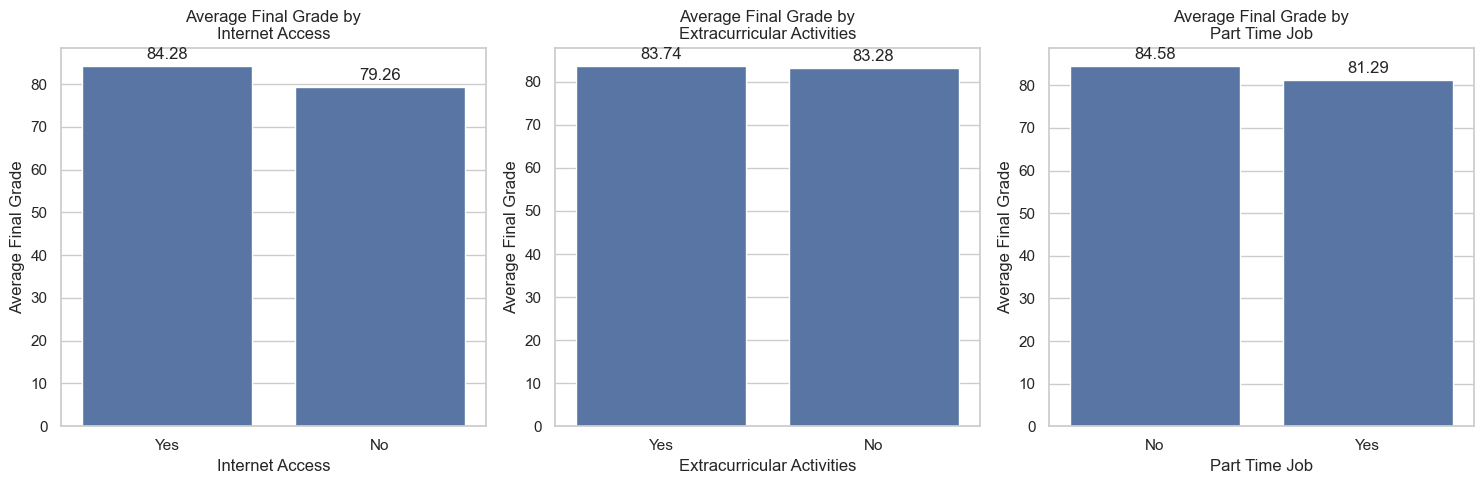

In [9]:
from scipy.stats import ttest_ind

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, var in zip(axes, categorical_variables):

    sns.barplot(
        data=df,
        x=var,
        y= target_variable[0],
        estimator='mean',
        errorbar=None,
        ax=ax
    )

    for container in ax.containers:
        ax.bar_label(container, fmt='%.2f', padding=3)

    ax.set_title(
        f'Average Final Grade by\n{var.replace("_", " ").title()}'
    )
    ax.set_xlabel(var.replace('_', ' ').title())
    ax.set_ylabel('Average Final Grade')

plt.tight_layout()
plt.show()

In [10]:
results = []

for var in categorical_variables:
    yes = df.loc[df[var] == 'Yes', target_variable[0]].dropna()
    no = df.loc[df[var] == 'No', target_variable[0]].dropna()

    # indipendent t-test
    t_stat, p_value = ttest_ind(
        yes,
        no,
        equal_var=False
    )

    results.append({
        'Variable': var,
        'Yes Mean': yes.mean(),
        'No Mean': no.mean(),
        'Mean Difference': yes.mean() - no.mean(),
        't-statistic': t_stat,
        'p-value': p_value,
        'Significant': 'Yes' if p_value < 0.05 else 'No'
    })

ttest_results = pd.DataFrame(results)
ttest_results.round(3)

,Variable,Yes Mean,No Mean,Mean Difference,t-statistic,p-value,Significant
0,internet_access,84.276,79.258,5.018,5.216,0.000,Yes
1,extracurricular_activities,83.737,83.284,0.453,0.694,0.488,No
2,part_time_job,81.295,84.582,-3.287,-4.555,0.000,Yes
